# Stage 0: the compiled program and the LHCb baselines

Every table is read from `results/`; every figure is made by `scripts/plots.py`. The README says which script writes which file.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.float_format', lambda v: '%.4g' % v)
methods = pd.read_csv('results/methods.csv')

## 1. The gate: the compiled methods against Python

In [2]:
pd.read_csv('results/gate_compiled_against_python.csv')

,method,map,tracks,field_reads_mean,gate_largest_difference_of_position_mm,gate_largest_difference_of_slope,gate_tracks_with_other_counts,gate_passed,fused_tracks_with_other_counts,fused_largest_difference_same_counts_mm,fused_largest_difference_all_tracks_mm,fused_within_limits,single_precision_median_um,single_precision_largest_um,fast_tanh_largest_difference_mm
0,rk4:16,cubic,1000,64,1.137e-13,1.11e-16,0,True,0,1.364e-12,1.364e-12,True,0.02667,0.5314,NaN
1,rk4:64,cubic,1000,256,2.274e-13,1.11e-16,0,True,0,4.547e-13,4.547e-13,True,0.04195,0.6534,NaN
2,rk4:16,linear,1000,64,0,0,0,True,0,4.547e-13,4.547e-13,True,0.02694,0.3355,NaN
3,rk4:64,linear,1000,256,0,0,0,True,0,9.095e-13,9.095e-13,True,0.04263,0.605,NaN
4,rec_cash_karp,linear,1000,38.45,0,0,0,True,1,1.059e-05,0.03764,True,0.01087,362.1,NaN
5,rec_cash_karp,cubic,1000,38.46,2.684e-11,9.905e-14,0,True,0,5.747e-09,5.747e-09,True,0.009819,26.03,NaN
6,allen_adaptive_nystrom,linear,1000,44.47,1.364e-12,6.939e-16,0,True,0,2.501e-12,2.501e-12,True,0.04353,4.1,NaN
7,allen_adaptive_nystrom,cubic,1000,44.52,2.728e-12,5.551e-16,0,True,0,4.093e-12,4.093e-12,True,0.04285,5.753,NaN
8,allen_fast_nystrom,linear,1000,11,0,0,0,True,0,4.547e-13,4.547e-13,True,0.01949,0.3106,NaN
9,allen_fast_nystrom,cubic,1000,11,1.137e-13,1.11e-16,0,True,0,4.547e-13,4.547e-13,True,0.02045,0.3104,NaN


## 2. The copy of the HLT2 integrator against the LHCb software

The grid of 1,331 states of the Rec test; the map the test used shows itself.

In [3]:
display(pd.read_csv('results/rec_copy_against_the_rec_reference.csv'))
display(pd.read_csv('../lhcb_software/rec_extrapolator_test/output/summary_stbc-i2.csv'))

,method,printed_by,map,states,states_printed_by_the_test,states_with_the_same_printed_numbers,states_within_one_last_digit,median_difference_of_position_um,percentile_99_of_difference_um,largest_difference_of_position_mm,field_reads_mean
0,rec_cash_karp,/cvmfs/lhcb.cern.ch/lib/lhcb/REC/REC_v41r3/Tr/TrackExtrapolators/tests/refs/test_extra...,v5r0_down,1331,1331,1331,1331,0.3369,0.4974,0.0005,78.78
1,rec_cash_karp,/cvmfs/lhcb.cern.ch/lib/lhcb/REC/REC_v41r3/Tr/TrackExtrapolators/tests/refs/test_extra...,v5r0_up,1331,1331,121,121,1.006e+06,2.584e+06,3101,78.78
2,rec_cash_karp,/cvmfs/lhcb.cern.ch/lib/lhcb/REC/REC_v41r3/Tr/TrackExtrapolators/tests/refs/test_extra...,v8r1_down,1331,1331,423,426,229.1,2212,5.787,78.56
3,rec_cash_karp,/cvmfs/lhcb.cern.ch/lib/lhcb/REC/REC_v41r3/Tr/TrackExtrapolators/tests/refs/test_extra...,v8r1_up,1331,1331,121,121,1.007e+06,2.583e+06,3101,78.56
4,rec_step,/data/bfys/gscriven/LHCb_Extrapolation_Project/Fast_extrapolator/lhcb_software/rec_ext...,v5r0_down,1331,1331,1331,1331,0.331,0.4965,0.0004994,63.36
5,rec_step,/data/bfys/gscriven/LHCb_Extrapolation_Project/Fast_extrapolator/lhcb_software/rec_ext...,v5r0_up,1331,1331,121,121,1.006e+06,2.584e+06,3102,63.36
6,rec_step,/data/bfys/gscriven/LHCb_Extrapolation_Project/Fast_extrapolator/lhcb_software/rec_ext...,v8r1_down,1331,1331,443,448,204.5,2180,4.968,63.83
7,rec_step,/data/bfys/gscriven/LHCb_Extrapolation_Project/Fast_extrapolator/lhcb_software/rec_ext...,v8r1_up,1331,1331,121,121,1.007e+06,2.584e+06,3102,63.83


,what,jobs,ns_a_state_lowest,ns_a_state_highest
0,Rec v41r3 in Gaudi: TrackRungeKuttaExtrapolator (adaptive Cash-Karp) with its transpor...,2,8127,8154
1,Rec v41r3 in Gaudi: TrackSTEPExtrapolator (adaptive Nystrom) with its transport matrix,2,9457,9549
2,our program: Cash-Karp copy state only,1,4548,5048
3,our program: Cash-Karp copy with transport matrix,1,7242,7627
4,our program: adaptive Nystrom (STEP) copy state only,1,6013,6390
5,our program: adaptive Nystrom (STEP) copy with transport matrix,1,9134,9544
6,our program: RK4 with one step (4 field reads),1,136.1,226.6


## 3. The LHCb methods on our tracks

In [4]:
cols = ['label', 'precision', 'field_reads_mean', 'field_reads_largest', 'ns_lowest', 'ns_median',
        'cold_ns_median', 'radial_median_um', 'radial_95_um', 'radial_99_um', 'fraction_above_100_um',
        'worst_band_median_um', 'flat_radial_median_um', 'flat_radial_95_um']
methods[methods.family == 'LHCb'][cols]

,label,precision,field_reads_mean,field_reads_largest,ns_lowest,ns_median,cold_ns_median,radial_median_um,radial_95_um,radial_99_um,fraction_above_100_um,worst_band_median_um,flat_radial_median_um,flat_radial_95_um
0,"HLT2 adaptive Nystrom (TrackSTEPExtrapolator, tolerance 5 um)",double,55.75,184,3609,3647,1.006e+04,10.11,38.8,73.67,0.005057,16.21,4.157,24.44
1,"HLT2 adaptive Nystrom (TrackSTEPExtrapolator, tolerance 5 um), with its transport matrix",double,55.75,184,5635,5704,1.232e+04,10.11,38.8,73.67,0.005057,16.21,4.157,24.44
2,"HLT2 adaptive Nystrom (TrackSTEPExtrapolator, tolerance 5 um), flat sample only",double,45.47,122,2865,3124,8221,4.157,24.44,44.12,0.003,14.46,4.157,24.44
3,"HLT2 adaptive Cash-Karp (TrackRungeKuttaExtrapolator, tolerance 1 um)",double,42.57,375,1825,1872,6472,22.16,112.2,215.5,0.06395,47.28,7.629,55.44
4,"HLT2 adaptive Cash-Karp (TrackRungeKuttaExtrapolator, tolerance 1 um), with its transp...",double,42.57,375,2918,3001,7794,22.16,112.2,215.5,0.06395,47.28,7.629,55.44
5,"HLT2 adaptive Cash-Karp (TrackRungeKuttaExtrapolator, tolerance 1 um), flat sample only",double,38.45,228,1710,2018,5972,7.629,55.44,137.3,0.021,44.19,7.629,55.44
6,"HLT1 adaptive Nystrom (Allen, tolerance 5 um)",float,54.75,187,3116,3188,1.115e+04,10.13,38.89,73.9,0.004983,16.22,4.136,24.4
7,"HLT1 adaptive Nystrom (Allen, tolerance 5 um), flat sample only",float,44.47,123,2659,2771,9478,4.136,24.4,44.57,0.003,14.95,4.136,24.4
8,"HLT1 T-track integrator (fixed Nystrom, 500 mm, 1 read a step)",float,11,11,742.8,753.2,3316,997.4,2834,3810,0.99,2689,309.8,1828
9,"HLT1 parametrised step (polynomials, no field read)",float,0,0,381.5,408.3,3366,55.65,2334,1.951e+04,0.4198,1175,5.283,499.6


In [5]:
bands = [c for c in methods.columns if c.startswith('radial_median_um_') and c.endswith('_gev')]
methods[methods.family == 'LHCb'][['label'] + bands]

,label,radial_median_um_0_3_gev,radial_median_um_3_8_gev,radial_median_um_8_20_gev,radial_median_um_20_50_gev,radial_median_um_above_50_gev
0,"HLT2 adaptive Nystrom (TrackSTEPExtrapolator, tolerance 5 um)",16.21,14.21,9.423,2.639,1.64
1,"HLT2 adaptive Nystrom (TrackSTEPExtrapolator, tolerance 5 um), with its transport matrix",16.21,14.21,9.423,2.639,1.64
2,"HLT2 adaptive Nystrom (TrackSTEPExtrapolator, tolerance 5 um), flat sample only",14.42,14.46,9.345,2.647,NaN
3,"HLT2 adaptive Cash-Karp (TrackRungeKuttaExtrapolator, tolerance 1 um)",47.28,35.03,14.22,3.119,0.3106
4,"HLT2 adaptive Cash-Karp (TrackRungeKuttaExtrapolator, tolerance 1 um), with its transp...",47.28,35.03,14.22,3.119,0.3106
5,"HLT2 adaptive Cash-Karp (TrackRungeKuttaExtrapolator, tolerance 1 um), flat sample only",44.19,35.35,10.44,3.587,NaN
6,"HLT1 adaptive Nystrom (Allen, tolerance 5 um)",16.22,14.18,9.43,2.635,1.647
7,"HLT1 adaptive Nystrom (Allen, tolerance 5 um), flat sample only",14.95,14.45,9.337,2.669,NaN
8,"HLT1 T-track integrator (fixed Nystrom, 500 mm, 1 read a step)",2689,1419,580.9,250.4,103.1
9,"HLT1 parametrised step (polynomials, no field read)",1175,164.1,11.94,3.315,1.607


The parametrised step of HLT1 against two field maps, and the check of our stored reference:

In [6]:
p = pd.read_csv('results/parametrised_step.csv')
p[['method', 'reference_map', 'radial_median_um', 'radial_95_um', 'worst_band_median_um', 'x_signed_median_um']]

,method,reference_map,radial_median_um,radial_95_um,worst_band_median_um,x_signed_median_um
0,"RK4, 4,096 steps, 2648.2 to 7826 mm, against the stored reference",v8r1_up,0.0001562,0.001035,0.0005029,-1.077e-05
1,"HLT1 parametrised step, polynomial, polarity +1",v8r1_up,55.65,2334,1175,0.7448
2,"HLT1 parametrised step, polynomial, polarity -1",v8r1_up,8.907e+05,2.545e+06,2.487e+06,9.636e+04
3,"HLT1 parametrised step, full, polarity +1",v8r1_up,1596,1.005e+04,9226,-57.19
4,"HLT1 parametrised step, full, polarity -1",v8r1_up,8.924e+05,2.556e+06,2.498e+06,9.644e+04
5,HLT2 integrator (Cash-Karp copy),v8r1_up,21.36,120.8,54.29,0.0211
6,"HLT1 T-track integrator (fixed Nystrom, 500 mm)",v8r1_up,966.4,2733,2592,-110.7
7,Straight line,v8r1_up,4.459e+05,1.262e+06,1.236e+06,4.82e+04
8,"HLT1 parametrised step, polynomial, polarity +1",v5r0_up,433,2722,1446,36.06
9,"HLT1 parametrised step, polynomial, polarity -1",v5r0_up,8.905e+05,2.544e+06,2.487e+06,9.631e+04


## 4. The unit costs: one field read and one network call

In [7]:
display(pd.read_csv('results/micro_field.csv'))
m = pd.read_csv('results/micro_mlp.csv')
m.pivot_table(index=['depth', 'width'], columns=['precision', 'activation'], values='ns_lowest')

,map,reader,precision,pattern,reads,ns_lowest,ns_median,checksum
0,v8r1_up,linear,double,random points,1048576,50.55,50.6,7.898e+05
1,v8r1_up,linear,double,along the tracks,860608,49.75,50.24,6.294e+05
2,v8r1_up,cubic,double,random points,1048576,103.8,136.1,7.9e+05
3,v8r1_up,cubic,double,along the tracks,860608,68.83,70.84,6.294e+05
4,v8r1_up,rec,double,random points,1048576,15.58,15.64,789.8
5,v8r1_up,rec,double,along the tracks,860608,14.38,14.47,629.4
6,v8r1_up,allen,double,random points,1048576,21.41,21.48,7.898e+05
7,v8r1_up,allen,double,along the tracks,860608,15.43,15.5,6.294e+05
8,v8r1_up,linear,float,random points,1048576,25.33,25.44,7.898e+05
9,v8r1_up,linear,float,along the tracks,860608,18.35,18.38,6.296e+05


precision      double                                                         \
activation       none tanh from the vector exponential tanh of the C library   
depth width                                                                    
1     8         63.24                             95.8                 335.7   
      16        49.51                            86.28                 406.2   
      32        58.04                            117.3                   616   
      64        89.54                            205.1                  1217   
      128       161.1                            397.7                  2429   
      256       344.8                            861.8                  4869   
      512       951.7                             1896                  9980   
2     8         48.58                            82.62                   319   
      16        81.24                            140.8                 610.1   
      32        121.9                            241.5                  1204   
      64        499.4                            749.3                  2666   
      128        1825                             2328                  6164   
      256        8108                             9265             1.712e+04   
      512   3.715e+04                        3.937e+04             5.382e+04   
3     8         62.44                              114                 447.7   
      16        115.9                            202.2                 857.7   
      32        179.1                            376.8                  1722   
      64        839.4                             1209                  3868   
      128        3415                             4162                  9460   
      256   1.559e+04                        1.736e+04             2.828e+04   
      512   6.708e+04                         7.03e+04              9.11e+04   

precision       float                                                         
activation       none tanh from the vector exponential tanh of the C library  
depth width                                                                   
1     8         25.36                               37                 178.3  
      16        32.77                            46.28                   323  
      32         44.6                             64.6                 614.3  
      64        53.16                            90.89                  1202  
      128       88.59                            161.3                  2400  
      256       153.6                              308                  4770  
      512       326.9                            626.9                  9575  
2     8         35.27                             67.2                 323.9  
      16        52.48                             79.8                 597.8  
      32        97.12                            134.9                  1193  
      64          151                            233.6                  2362  
      128       913.2                             1078                  5324  
      256        3335                             3660             1.219e+04  
      512   1.712e+04                        1.781e+04             3.503e+04  
3     8         45.31                            97.73                 455.8  
      16        73.25                            113.9                 843.2  
      32        156.8                              214                  1698  
      64        386.3                            506.7                  3456  
      128        1728                             1971                  7835  
      256        7211                             7726             1.951e+04  
      512   3.138e+04                        3.232e+04             5.662e+04

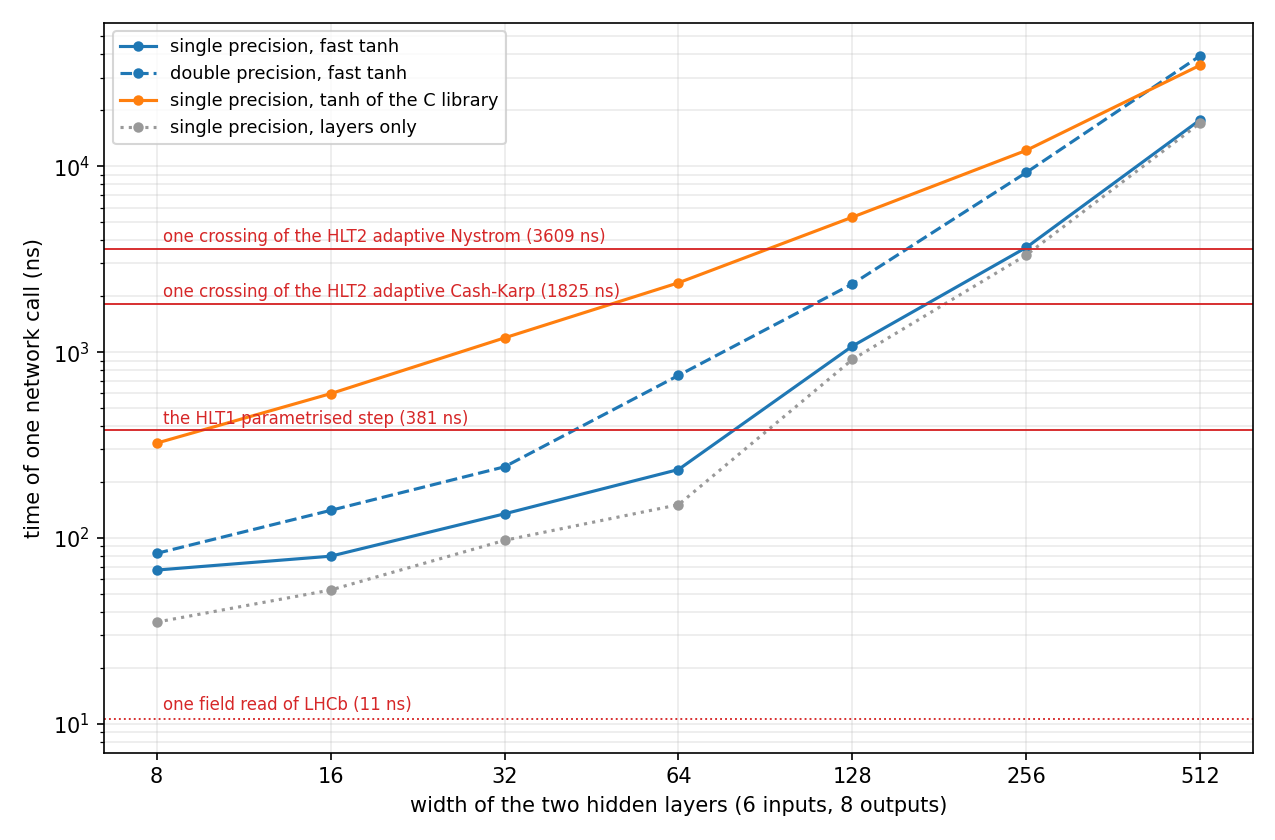

In [8]:
display(Image('figures/cost_of_a_network_call.png'))

## 5. Every method: time and error

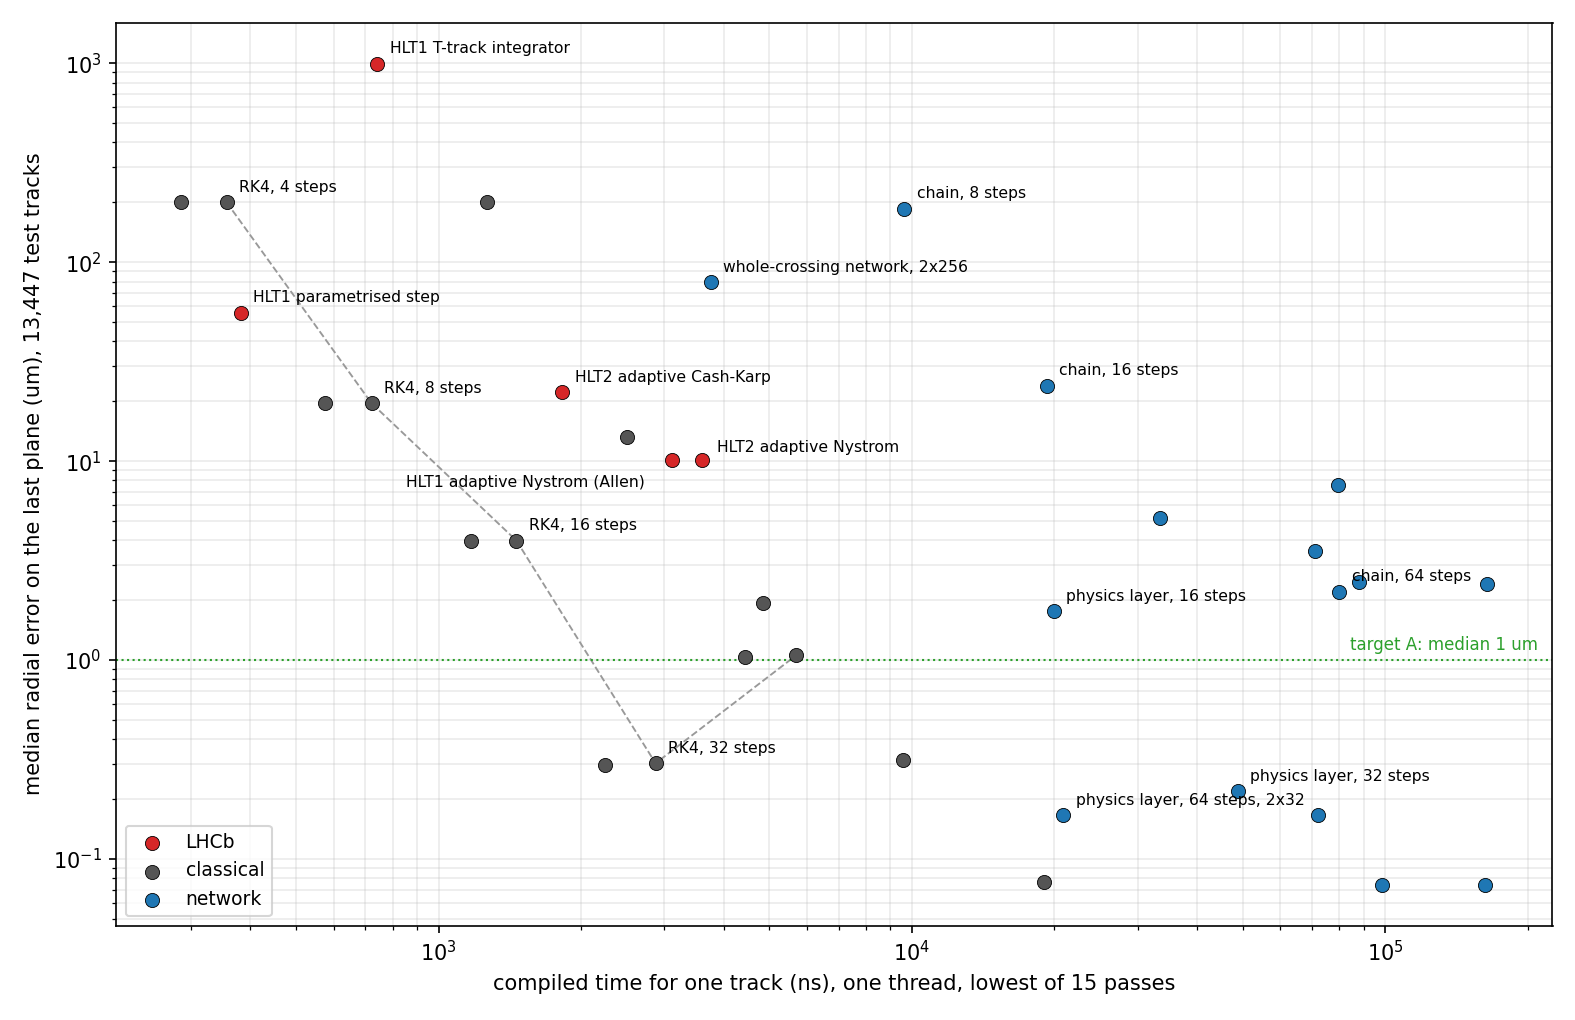

In [9]:
display(Image('figures/time_against_error.png'))

In [10]:
methods[methods.family == 'classical'][cols]

,label,precision,field_reads_mean,field_reads_largest,ns_lowest,ns_median,cold_ns_median,radial_median_um,radial_95_um,radial_99_um,fraction_above_100_um,worst_band_median_um,flat_radial_median_um,flat_radial_95_um
10,"RK4, 4 steps, linear map",double,16,16,404.4,427,2414,200.1,2990,1.179e+04,0.7093,767,49.67,876.1
11,"RK4, 4 steps, linear map",float,16,16,356.5,370.8,2074,200.1,2991,1.179e+04,0.7095,767.1,49.7,876.2
12,"RK4, 4 steps, cubic map",double,16,16,1343,1391,7284,200.8,2891,1.22e+04,0.7116,774.3,49.52,879.1
13,"RK4, 4 steps, cubic map",float,16,16,1265,1290,6943,200.9,2891,1.22e+04,0.7117,774.5,49.52,879.1
14,"RK4, 4 steps, linear map, field read of LHCb",float,16,16,286.3,302.3,1914,200.1,2991,1.179e+04,0.7096,767.3,49.71,876.2
15,"RK4, 8 steps, linear map",double,32,32,810.3,856.4,4008,19.5,145.4,1963,0.08009,67.12,5.241,58.67
16,"RK4, 8 steps, linear map",float,32,32,721.5,745.6,3456,19.56,145.6,1963,0.08032,67.3,5.265,58.89
17,"RK4, 8 steps, cubic map",double,32,32,2655,2748,1.15e+04,13.16,211.1,3285,0.08151,52.32,3.157,51.99
18,"RK4, 8 steps, cubic map",float,32,32,2506,2575,1.07e+04,13.23,211.2,3285,0.08158,52.4,3.171,52.18
19,"RK4, 8 steps, linear map, field read of LHCb",float,32,32,574.5,611.7,3326,19.59,145.7,1963,0.08039,67.4,5.265,58.83


In [11]:
methods['precision and tanh'] = methods['precision'] + methods['tanh'].fillna('').map(lambda t: ', fast tanh' if t == 'fast' else '')
methods[methods.family == 'network'][['label', 'precision and tanh', 'network_calls', 'multiply_adds_a_call'] + cols[2:]]

,label,precision and tanh,network_calls,multiply_adds_a_call,field_reads_mean,field_reads_largest,ns_lowest,ns_median,cold_ns_median,radial_median_um,radial_95_um,radial_99_um,fraction_above_100_um,worst_band_median_um,flat_radial_median_um,flat_radial_95_um
35,"Whole-crossing network, 2x256, linear map",double,1,67840,0,0,1.841e+04,1.9e+04,5.184e+04,79.38,773.7,4102,0.4121,233.6,40.27,274.8
36,"Whole-crossing network, 2x256, linear map",float,1,67840,0,0,1.36e+04,1.384e+04,3.297e+04,79.45,773.7,4102,0.4124,233.6,40.31,274.9
37,"Whole-crossing network, 2x256, linear map","float, fast tanh",1,67840,0,0,3756,3876,2.272e+04,79.37,773.7,4102,0.4124,233.6,40.29,274.9
38,"Chain, direct states, 64 steps, 2x128, cubic map",double,64,18176,128,128,3.875e+05,3.888e+05,4.659e+05,7.644,93.65,291.3,0.04626,31.38,3.816,43.64
39,"Chain, direct states, 64 steps, 2x128, cubic map",float,64,18176,128,128,3.296e+05,3.303e+05,3.569e+05,7.638,93.59,291.5,0.04611,31.43,3.811,43.66
40,"Chain, direct states, 64 steps, 2x128, cubic map","float, fast tanh",64,18176,128,128,7.943e+04,8.105e+04,1.119e+05,7.622,93.58,291.4,0.04611,31.43,3.796,43.69
41,"Chain, straight line, global scale, 64 steps, 2x128, cubic map",double,64,18176,128,128,4.318e+05,4.369e+05,5.127e+05,3.545,36.14,121.5,0.01353,13.34,2.48,14.05
42,"Chain, straight line, global scale, 64 steps, 2x128, cubic map",float,64,18176,128,128,3.721e+05,3.742e+05,4.177e+05,3.541,36.13,121.5,0.01353,13.4,2.48,14.06
43,"Chain, straight line, global scale, 64 steps, 2x128, cubic map","float, fast tanh",64,18176,128,128,7.114e+04,7.349e+04,1.227e+05,3.542,36.13,121.5,0.01353,13.4,2.48,14.06
44,"Chain, straight line, per-track scale (16 samples), 64 steps, 2x128, cubic map",double,64,18176,1152,1152,5.176e+05,5.193e+05,5.966e+05,2.404,17.56,71.52,0.007214,7.507,1.899,10.53


## 6. The error by momentum

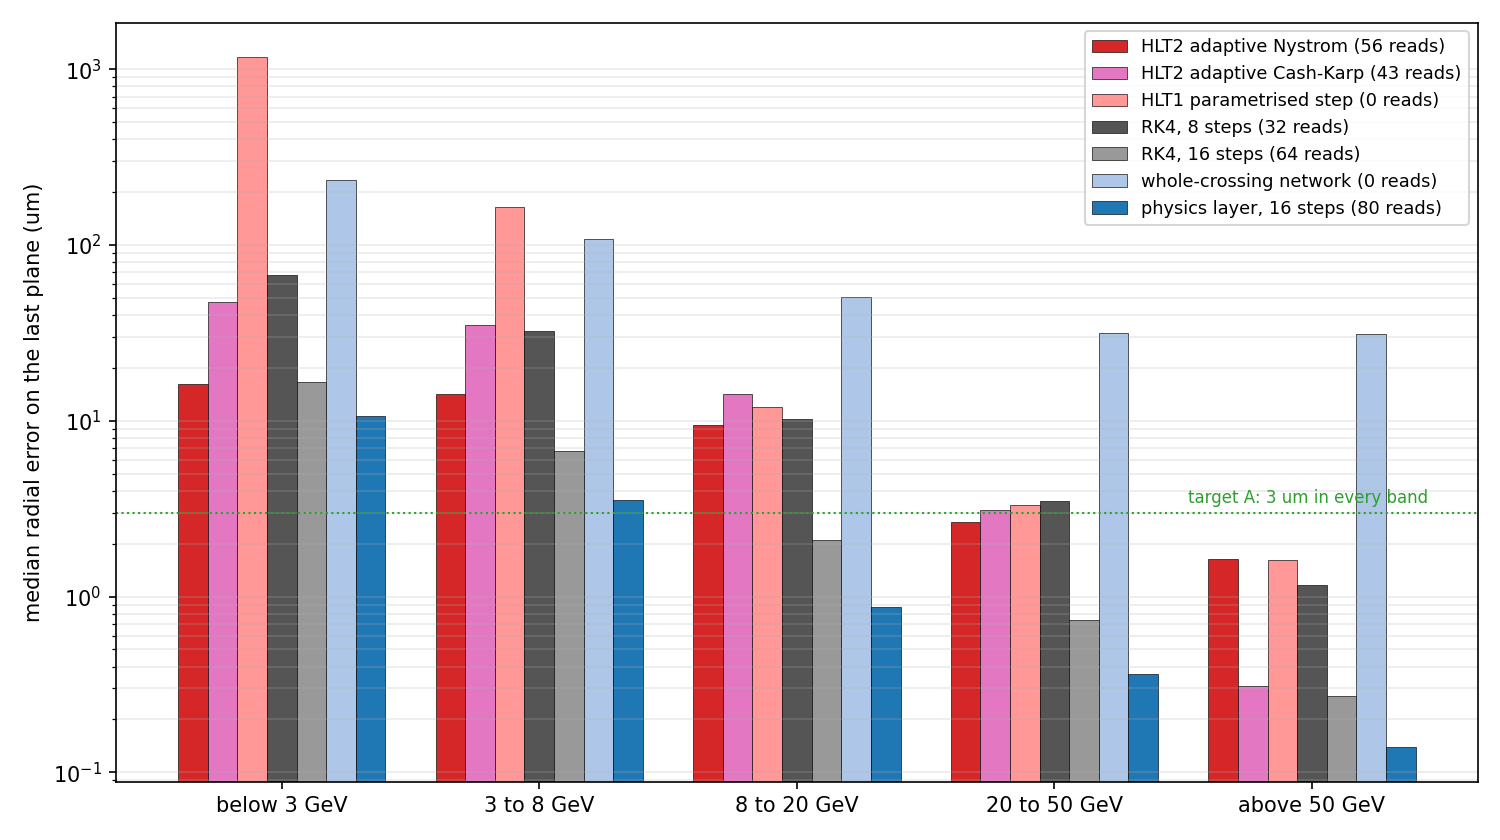

In [12]:
display(Image('figures/error_by_momentum.png'))

## 7. The transport matrix of the copy against finite differences

In [13]:
pd.read_csv('results/transport_matrix_of_the_copy.csv')

,element,median_of_copy,median_of_differences,median_relative_difference,percentile_95_relative_difference,same_sign_fraction
0,d x / d tx0,5188,5188,9.112e-05,0.002097,1
1,d x / d ty0,-0.04013,1.855,0.8887,1.026,0.928
2,d x / d qop0,-9983,-9983,8.197e-05,0.0007706,1
3,d y / d tx0,0.1089,0.04082,0.09862,0.3433,0.994
4,d y / d ty0,5181,5180,0.000245,0.01122,1
5,d y / d qop0,3.506,3.375,0.04246,0.5772,0.987
6,d tx / d tx0,1.005,1.005,0.0002752,0.005988,1
7,d tx / d ty0,1.502e-05,0.0005923,0.6075,0.8292,0.992
8,d tx / d qop0,-3.785,-3.785,0.0001553,0.002234,1
9,d ty / d tx0,6.62e-06,1.687e-06,0.4207,1.08,0.962
